# Notebook 04 · Evaluation and failure study

Workbook 1 activity **G (Evaluation & failure study)** and GitHub issue **#14 (298-33)**. It compares the **reproduced baseline** (Notebook 02) with **Model 1** (Notebook 03a, headset test) on the same 16 AMI test meetings and answers four questions:

| Section | Question | Used for |
|---|---|---|
| 1 | **Who gets hurt?** Attribution error per person: women vs men, native vs non-native English, quiet vs talkative | Novelty (fairness, accents) · Workbook 2 §3.6 coverage gap |
| 2 | **What goes wrong?** Every error region sorted into a failure type, counted, with 60 cases for a person to check | Presentation slide 7 · D-06 |
| 3 | **What does each part cost?** Scoring ablations: forgive boundaries, ignore overlap | Presentation slide 6 |
| 4 | **Where does Model 1 lose?** Meetings and failure types where it is worse than the baseline | Presentation slide 8 |

**Runs on CPU in a few minutes.** Use the **Python (pyannote 2.1)** kernel (Notebook 02); it only needs `pyannote.core`, `pyannote.metrics` and pandas. It reads saved RTTM files and runs no model.

If Model 1 (Notebook 03a) has not been run yet, set `M1_RTTM = None`: every section then runs for the baseline alone.

## Settings

In [1]:
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyannote.core import Annotation, Segment, Timeline
from pyannote.database.util import load_rttm, load_uem
from pyannote.metrics.diarization import DiarizationErrorRate


WORK      = Path("/workspace")
SETUP     = WORK / "AMI-diarization-setup"
TABLES    = WORK / "data_processed" / "tables"
RESULTS   = WORK / "results" / "data"                    # Notebook 01 saved speaker metadata here
WAREHOUSE = WORK / "warehouse" / "ami.duckdb"

SPLIT         = "test"
REFERENCE_SET = "only_words"
COLLAR        = 0.0
SKIP_OVERLAP  = False
SEED          = 42


# 1. The two systems to compare (RTTM folders)

BASELINE_RUN = WORK / "results" / "pyannote21_baseline" / SPLIT / "20261106_085354"

m1_runs = sorted((WORK / "results" / "model1_finetuned_segmentation").glob("*/rttm/model1_headset_test"))
M1_RTTM = WORK / "results" / "model1_finetuned_segmentation" / "20261106_182403" / "rttm" / "model1_headset_test"
assert M1_RTTM.exists(), M1_RTTM

SYSTEMS = {"baseline": BASELINE_RUN / "rttm"}
if M1_RTTM is not None:
    SYSTEMS["model1"] = M1_RTTM
for name, folder in SYSTEMS.items():
    assert folder.exists(), f"{name}: RTTM folder not found: {folder}"
    print(f"{name:9s}: {folder}")
if M1_RTTM  is None:
    print("Model 1 not found - running for the baseline only.")


# 2. Rules of the failure study (fixed before looking at the cases)

FRAME            = 0.1     # seconds per frame when locating errors
MERGE_GAP        = 0.2     # error frames closer than this belong to one error event
MIN_EVENT        = 0.3     # shorter error events are ignored
SHORT_TURN       = 1.0     # a reference turn shorter than this is a "short reply"
BOUNDARY_WINDOW  = 0.5     # an error this close to a change of speaker is a "speaker change" error
QUIET_SHARE      = 0.15    # a person with less than 15% of the meeting's talk time is "quiet"
CASES_TO_REVIEW  = 60      # the presentation asks for a taxonomy over 50+ cases


# 3. Output folder

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
OUT = WORK / "results" / "evaluation" / SPLIT / RUN_ID
(OUT / "figures").mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)

print("Python:", sys.executable)
print("Run ID:", RUN_ID, "| results go to:", OUT)

baseline : /workspace/results/pyannote21_baseline/test/20261106_085354/rttm
model1   : /workspace/results/model1_finetuned_segmentation/20261106_182403/rttm/model1_headset_test
Python: /workspace/envs/pyannote21/bin/python
Run ID: 20261107_090253 | results go to: /workspace/results/evaluation/test/20261107_090253


## Load references, both systems, and speaker information

In [2]:
# 1. Meetings, reference speakers, scored regions

meetings   = (SETUP / "lists" / f"{SPLIT}.meetings.txt").read_text().split()
references = {m: load_rttm(SETUP / REFERENCE_SET / "rttms" / SPLIT / f"{m}.rttm")[m] for m in meetings}
uems       = {m: load_uem(SETUP / "uems" / SPLIT / f"{m}.uem")[m] for m in meetings}


# 2. Each system's answers

hypotheses = {}
for name, folder in SYSTEMS.items():
    hypotheses[name] = {}
    for m in meetings:
        file = folder / f"{m}.rttm"
        assert file.exists(), f"{name}: missing {file}"
        hypotheses[name][m] = load_rttm(file).get(m, Annotation(uri=m))


# 3. Speaker information from Notebook 01 (sex, native language)

meta_files = sorted(RESULTS.glob("speaker_metadata_*.csv"))
assert meta_files, f"No speaker_metadata_*.csv in {RESULTS} - run Notebook 01."
speaker_meta = pd.read_csv(meta_files[-1])
speaker_meta = speaker_meta[speaker_meta["split"] == SPLIT].drop_duplicates("speaker").set_index("speaker")


# 4. Reference words (to show what was said in each failure case)

words = pd.read_parquet(TABLES / "words.parquet")
words = words[(words["split"] == SPLIT) & (~words["is_punct"])]

print(f"{len(meetings)} meetings | systems: {list(SYSTEMS)} | {len(speaker_meta)} speakers with metadata ({meta_files[-1].name})")
print("Speakers by sex:", speaker_meta["sex"].value_counts().to_dict())
print("Speakers by first language:", speaker_meta["first_language"].value_counts().to_dict())


# 5. Check: the baseline still scores 19.52% here (same files, same rules as Notebook 02, run 20261106_085354)

NOTEBOOK02_DER = 19.52
check = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
for m in meetings:
    check(references[m], hypotheses["baseline"][m], uem=uems[m])
recomputed = abs(check) * 100
print(f"Baseline DER recomputed: {recomputed:.2f}%  (Notebook 02: {NOTEBOOK02_DER}%)")
assert abs(recomputed - NOTEBOOK02_DER) < 0.05, "Baseline DER differs from Notebook 02 - wrong run folder or scoring rules?"


16 meetings | systems: ['baseline', 'model1'] | 16 speakers with metadata (speaker_metadata_20261106_080237.csv)
Speakers by sex: {'F': 8, 'M': 8}
Speakers by first language: {'English': 6, 'other': 6, 'unknown': 4}
Baseline DER recomputed: 19.52%  (Notebook 02: 19.52%)


## 1 · Who gets hurt? Attribution error per person

For each real person: how much of their speech is given to **them** (correct), to **someone else** (confused), or to **nobody** (missed)?

* The model's speakers are matched to real people with the same optimal mapping DER uses.
* **Attribution error** = share of a person's speaking time that is not credited to them.
* Groups: sex, first language (English / other / unknown), and talk share (quiet = less than 15% of the meeting's talk time).

**Read with care:** the test split has only 16 people, so groups have 4 to 8 people each. The ranges are bootstrap 95% ranges over people. Treat these results as a first signal, not proof. Running Notebooks 02 and 03 on the **dev** split as well gives 37 people.

In [3]:
mapper = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)


def per_person(reference, hypothesis, uem):
    """One row per real person: total speech, correct, confused, missed (seconds), also inside overlap."""

    ref = reference.crop(uem)
    hyp = hypothesis.crop(uem)
    mapping = mapper.optimal_mapping(ref, hyp)                 # model label -> real person
    hyp_named = hyp.rename_labels(mapping)
    hyp_speech = hyp.get_timeline().support()
    overlap = ref.get_timeline().get_overlap()
    meeting_speech = sum(ref.label_timeline(s).support().duration() for s in ref.labels())

    rows = []
    for person in ref.labels():
        own = ref.label_timeline(person).support()
        credited = hyp_named.label_timeline(person).support() if person in hyp_named.labels() else Timeline()
        own_overlap = own.crop(overlap, mode="intersection")

        total      = own.duration()
        correct    = own.crop(credited, mode="intersection").duration() if credited else 0.0
        heard      = own.crop(hyp_speech, mode="intersection").duration()
        ov_total   = own_overlap.duration()
        ov_correct = own_overlap.crop(credited, mode="intersection").duration() if credited and ov_total else 0.0

        rows.append({"person": person, "speech_s": total, "correct_s": correct,
                     "confused_s": heard - correct, "missed_s": total - heard,
                     "talk_share": total / meeting_speech,
                     "overlap_s": ov_total, "overlap_correct_s": ov_correct})
    return rows


people = []
for name in SYSTEMS:
    for m in meetings:
        for row in per_person(references[m], hypotheses[name][m], uems[m]):
            people.append({"system": name, "meeting": m, **row})

people = pd.DataFrame(people)
people["attribution_error_%"]         = 100 * (1 - people["correct_s"] / people["speech_s"])
people["overlap_attribution_error_%"] = 100 * (1 - people["overlap_correct_s"] / people["overlap_s"].replace(0, np.nan))
people["sex"]            = people["person"].map(speaker_meta["sex"]).fillna("unknown")
people["first_language"] = people["person"].map(speaker_meta["first_language"]).fillna("unknown")
people["talk_group"]     = np.where(people["talk_share"] < QUIET_SHARE, "quiet (<15%)", "talkative (>=15%)")

people.to_csv(OUT / "per_person_attribution.csv", index=False)
print(f"{people['person'].nunique()} people x {len(SYSTEMS)} systems")
people.sort_values(["person", "system"]) \
    [["system", "meeting", "person", "sex", "first_language", "talk_share", "attribution_error_%", "overlap_attribution_error_%"]].round(3)

16 people x 2 systems


,system,meeting,person,sex,first_language,talk_share,attribution_error_%,overlap_attribution_error_%
16,baseline,ES2004a,FEE013,F,English,0.422,11.094,42.550
20,baseline,ES2004b,FEE013,F,English,0.334,6.518,22.260
24,baseline,ES2004c,FEE013,F,English,0.268,10.605,34.194
28,baseline,ES2004d,FEE013,F,English,0.278,13.463,34.573
79,model1,ES2004a,FEE013,F,English,0.422,13.046,49.123
...,...,...,...,...,...,...,...,...
47,baseline,TS3003d,MTD012ME,M,unknown,0.197,18.069,41.981
98,model1,TS3003a,MTD012ME,M,unknown,0.107,25.496,53.541
102,model1,TS3003b,MTD012ME,M,unknown,0.318,4.440,36.139
106,model1,TS3003c,MTD012ME,M,unknown,0.236,11.211,47.879


In [4]:
def group_table(frame, column, n_boot=2000):

    rows = []
    for (system, group), part in frame.groupby(["system", column]):
        by_person = part.groupby("person")[["speech_s", "correct_s", "missed_s", "confused_s",
                                            "overlap_s", "overlap_correct_s"]].sum()
        wrong = (by_person["speech_s"] - by_person["correct_s"]).values
        speech = by_person["speech_s"].values
        boot = []
        for _ in range(n_boot):
            pick = rng.integers(0, len(by_person), len(by_person))
            boot.append(100 * wrong[pick].sum() / speech[pick].sum())
        low, high = np.percentile(boot, [2.5, 97.5])
        overlap_total = by_person["overlap_s"].sum()
        rows.append({"system": system, "dimension": column, "group": group,
                     "people": len(by_person), "person_meetings": len(part),
                     "attribution_error_%": 100 * wrong.sum() / speech.sum(),
                     "range_low": low, "range_high": high,
                     "missed_%": 100 * by_person["missed_s"].sum() / speech.sum(),
                     "confused_%": 100 * by_person["confused_s"].sum() / speech.sum(),
                     "in_overlap_error_%": (100 * (1 - by_person["overlap_correct_s"].sum() / overlap_total)
                                            if overlap_total else np.nan)})
    return pd.DataFrame(rows)


fairness = pd.concat([group_table(people, c) for c in ["sex", "first_language", "talk_group"]], ignore_index=True)
fairness.to_csv(OUT / "fairness_by_group.csv", index=False)
print(fairness.round(2).to_string(index=False))
print("\nNOTE: groups with fewer than 5 distinct people are single cases, not averages - report them as a first signal only.")


  system      dimension             group  people  person_meetings  attribution_error_%  range_low  range_high  missed_%  confused_%  in_overlap_error_%
baseline            sex                 F       8               31                13.08       9.45       17.33      1.39       11.69               36.92
baseline            sex                 M       8               32                15.30       9.56       20.58      2.70       12.59               40.10
  model1            sex                 F       8               31                13.87       9.99       18.11      1.69       12.18               39.42
  model1            sex                 M       8               32                16.84      11.39       22.17      3.52       13.32               43.69
baseline first_language           English       6               24                14.76       7.99       20.06      1.40       13.36               37.53
baseline first_language             other       6               23                

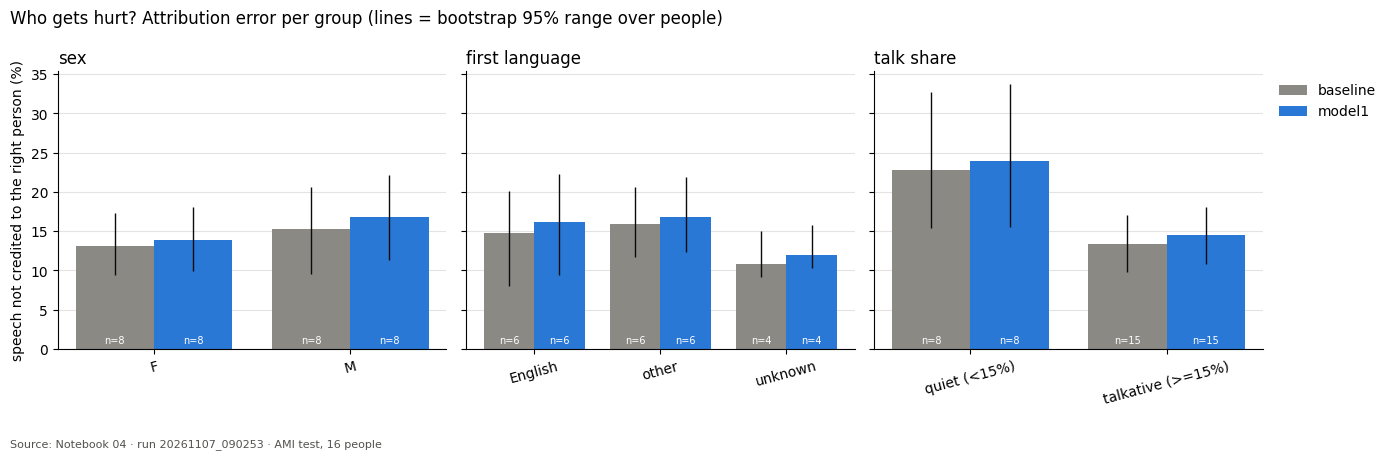

Saved: /workspace/results/evaluation/test/20261107_090253/figures/fairness_by_group.png


In [5]:
# Figure: attribution error per group, one panel per dimension, one bar per system

COLORS = {"baseline": "#8a8984", "model1": "#2a78d6"}
INK, NEUTRAL = "#0b0b0b", "#52514e"
dimensions = ["sex", "first_language", "talk_group"]
titles = {"sex": "sex", "first_language": "first language", "talk_group": "talk share"}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
width = 0.8 / len(SYSTEMS)
for ax, dimension in zip(axes, dimensions):
    part = fairness[fairness["dimension"] == dimension]
    groups = sorted(part["group"].unique())
    x = np.arange(len(groups))
    for k, system in enumerate(SYSTEMS):
        rows = part[part["system"] == system].set_index("group").reindex(groups)
        offset = (k - (len(SYSTEMS) - 1) / 2) * width
        ax.bar(x + offset, rows["attribution_error_%"], width=width, color=COLORS[system], label=system)
        ax.vlines(x + offset, rows["range_low"], rows["range_high"], color=INK, linewidth=1)
        for xi, n in zip(x + offset, rows["people"]):
            ax.text(xi, 0.5, f"n={int(n)}", ha="center", va="bottom", fontsize=7, color="white")
    ax.set_xticks(x)
    ax.set_xticklabels(groups, rotation=15)
    ax.set_title(titles[dimension], loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("speech not credited to the right person (%)")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.suptitle("Who gets hurt? Attribution error per group (lines = bootstrap 95% range over people)", x=0.01, ha="left")
fig.text(0.01, -0.06, f"Source: Notebook 04 · run {RUN_ID} · AMI {SPLIT}, {people['person'].nunique()} people",
         fontsize=8, color=NEUTRAL)
plt.tight_layout()
figure_file = OUT / "figures" / "fairness_by_group.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

## 2 · What goes wrong? Failure taxonomy

1. Cut every meeting into 0.1 s frames. In each frame, compare who really spoke with who the model said spoke (after matching speakers). Count missed, false-alarm and confused speakers, as DER does.
2. Join neighbouring error frames into **error events** (gaps ≤ 0.2 s, length ≥ 0.3 s).
3. Give each event **one failure type**, using the first rule that fits:

| # | Failure type | Rule |
|---|---|---|
| 1 | overlapped speech | at least half of the event has 2+ real speakers |
| 2 | invented speaker | at least half of the event goes to a model speaker that matches no real person |
| 3 | short reply / backchannel | a real turn in the event is shorter than 1 s ("yeah", "okay") |
| 4 | speaker change | the event is shorter than 1.5 s and within 0.5 s of one person handing over to another |
| 5 | quiet speaker | the person involved has less than 15% of the meeting's talk time |
| 6 | false alarm in silence | most of the event has no real speaker |
| 7 | missed speech / confusion | everything else, by the main error kind |

4. Count events and **error seconds** per type, and draw **60 cases** (up to 9 per type) for a person to listen to and confirm. The presentation asks for a taxonomy over 50+ cases.

The rules are fixed **before** looking at the cases, so the counts are not tuned to a story.

In [6]:
def frame_matrix(annotation, labels, start, n_frames):
    """Boolean matrix [label, frame]: is this label speaking in this frame?"""

    active = np.zeros((len(labels), n_frames), dtype=bool)
    index = {label: i for i, label in enumerate(labels)}
    for segment, _, label in annotation.itertracks(yield_label=True):
        a = max(0, int(np.floor((segment.start - start) / FRAME)))
        b = min(n_frames, int(np.ceil((segment.end - start) / FRAME)))
        if b > a:
            active[index[label], a:b] = True
    return active


def error_events(meeting, system):

    reference = references[meeting].crop(uems[meeting])
    hypothesis = hypotheses[system][meeting].crop(uems[meeting])
    extent = uems[meeting].extent()
    n_frames = int(np.ceil(extent.duration / FRAME))
    mapping = mapper.optimal_mapping(reference, hypothesis)
    named = hypothesis.rename_labels(mapping)

    people_labels = sorted(reference.labels())
    model_labels = sorted(named.labels())
    invented = [l for l in model_labels if l not in people_labels]
    ref_active = frame_matrix(reference, people_labels, extent.start, n_frames)
    hyp_active = frame_matrix(named, model_labels, extent.start, n_frames)

    n_ref = ref_active.sum(0)
    n_hyp = hyp_active.sum(0)
    shared = np.zeros(n_frames, dtype=int)
    for i, person in enumerate(people_labels):
        if person in model_labels:
            shared += ref_active[i] & hyp_active[model_labels.index(person)]
    miss = np.maximum(0, n_ref - n_hyp)
    fa = np.maximum(0, n_hyp - n_ref)
    conf = np.minimum(n_ref, n_hyp) - shared
    error = (miss + fa + conf) > 0
    invented_active = hyp_active[[model_labels.index(l) for l in invented]].any(0) if invented else np.zeros(n_frames, bool)


    # 1. Join error frames into events

    events, i = [], 0
    max_gap = int(round(MERGE_GAP / FRAME))
    while i < n_frames:
        if not error[i]:
            i += 1
            continue
        j, last = i, i
        while j < n_frames and (error[j] or j - last <= max_gap):
            if error[j]:
                last = j
            j += 1
        if (last + 1 - i) * FRAME >= MIN_EVENT:
            events.append((i, last + 1))
        i = last + 1


    # 2. Facts the rules need

    turns = [(s.start, s.end, l) for s, _, l in reference.itertracks(yield_label=True)]
    talk_share = {p: reference.label_timeline(p).support().duration() for p in people_labels}
    total_talk = sum(talk_share.values()) or 1.0
    changes = np.array(sorted(s for k, (s, e, l) in enumerate(turns)
                              if any(l2 != l and abs(e2 - s) <= BOUNDARY_WINDOW for s2, e2, l2 in turns)))

    rows = []
    for a, b in events:
        t0, t1 = extent.start + a * FRAME, extent.start + b * FRAME
        span = slice(a, b)
        involved = [(s, e, l) for s, e, l in turns if s < t1 and e > t0]
        persons = sorted({l for _, _, l in involved})
        shortest = min((e - s for s, e, _ in involved), default=np.inf)
        near_change = bool(len(changes)) and np.min(np.abs(changes - (t0 + t1) / 2)) <= BOUNDARY_WINDOW + (t1 - t0) / 2
        quiet = any(talk_share[p] / total_talk < QUIET_SHARE for p in persons)
        kinds = {"missed": miss[span].sum(), "false alarm": fa[span].sum(), "confusion": conf[span].sum()}

        if (n_ref[span] >= 2).mean() >= 0.5:
            category = "overlapped speech"
        elif invented_active[span].mean() >= 0.5:
            category = "invented speaker"
        elif shortest < SHORT_TURN:
            category = "short reply / backchannel"
        elif near_change and (t1 - t0) < 1.5:
            category = "speaker change"
        elif quiet:
            category = "quiet speaker"
        elif (n_ref[span] == 0).mean() >= 0.5:
            category = "false alarm in silence"
        else:
            category = "missed speech" if kinds["missed"] >= max(kinds["false alarm"], kinds["confusion"]) else "speaker confusion"

        rows.append({"system": system, "meeting": meeting, "start": round(t0, 2), "end": round(t1, 2),
                     "duration_s": round(t1 - t0, 2), "category": category,
                     "main_error": max(kinds, key=kinds.get),
                     "error_s": round(FRAME * float(miss[span].sum() + fa[span].sum() + conf[span].sum()), 2),
                     "real_speakers": ", ".join(persons) or "-",
                     "max_simultaneous": int(n_ref[span].max())})
    return rows


events = pd.DataFrame([row for system in SYSTEMS for m in meetings for row in error_events(m, system)])
events.to_csv(OUT / "failure_events_all.csv", index=False)

taxonomy = (events.groupby(["system", "category"])
                  .agg(events=("category", "size"), error_min=("error_s", lambda s: s.sum() / 60))
                  .reset_index())
taxonomy["share_of_error_%"] = 100 * taxonomy["error_min"] / taxonomy.groupby("system")["error_min"].transform("sum")
taxonomy = taxonomy.sort_values(["system", "error_min"], ascending=[True, False])
taxonomy.to_csv(OUT / "failure_taxonomy.csv", index=False)
print(f"Error events: {len(events):,} across {len(SYSTEMS)} system(s)\n")
print(taxonomy.round(2).to_string(index=False))

Error events: 8,295 across 2 system(s)

  system                  category  events  error_min  share_of_error_%
baseline         overlapped speech    2145      59.70             60.66
baseline short reply / backchannel     600      13.38             13.60
baseline    false alarm in silence     468       7.80              7.93
baseline             missed speech     296       5.79              5.89
baseline          invented speaker     132       5.00              5.08
baseline         speaker confusion     182       3.14              3.20
baseline            speaker change     167       2.00              2.03
baseline             quiet speaker      61       1.59              1.62
  model1         overlapped speech    2462      62.91             63.73
  model1 short reply / backchannel     589      12.87             13.03
  model1    false alarm in silence     460       8.11              8.21
  model1             missed speech     321       6.44              6.53
  model1          invent

In [7]:
# Top three causes per system, and what we would do about each (from Workbook 1's design)

ACTIONS = {
    "overlapped speech":         "Overlap-aware segmentation with more simultaneous speakers; joint ASR-diarization (M3).",
    "invented speaker":          "Stricter clustering threshold or minimum cluster size; give the expected number of speakers when known.",
    "short reply / backchannel": "Lower the minimum turn length; join a short reply to the overlapping turn it answers.",
    "speaker change":            "Finer frame step at turn changes; smooth only within one speaker.",
    "quiet speaker":             "Do not merge small clusters into large ones; check per-person recall during tuning.",
    "false alarm in silence":    "Stricter speech-activity threshold; remove non-speech noise (laughs, keyboard).",
    "missed speech":             "Lower the speech-activity threshold; check far-field and quiet voices.",
    "speaker confusion":         "Better speaker embeddings (WavLM in DiariZen); re-clustering after a first pass.",
}

top3 = taxonomy.groupby("system").head(3).assign(what_we_would_do=lambda t: t["category"].map(ACTIONS))
top3.to_csv(OUT / "top3_causes.csv", index=False)
for system, part in top3.groupby("system", sort=False):
    print(f"\n{system}: top three causes by error time")
    for _, row in part.iterrows():
        print(f"  {row['category']:27s} {row['error_min']:6.1f} min ({row['share_of_error_%']:4.1f}%)  -> {row['what_we_would_do']}")


baseline: top three causes by error time
  overlapped speech             59.7 min (60.7%)  -> Overlap-aware segmentation with more simultaneous speakers; joint ASR-diarization (M3).
  short reply / backchannel     13.4 min (13.6%)  -> Lower the minimum turn length; join a short reply to the overlapping turn it answers.
  false alarm in silence         7.8 min ( 7.9%)  -> Stricter speech-activity threshold; remove non-speech noise (laughs, keyboard).

model1: top three causes by error time
  overlapped speech             62.9 min (63.7%)  -> Overlap-aware segmentation with more simultaneous speakers; joint ASR-diarization (M3).
  short reply / backchannel     12.9 min (13.0%)  -> Lower the minimum turn length; join a short reply to the overlapping turn it answers.
  false alarm in silence         8.1 min ( 8.2%)  -> Stricter speech-activity threshold; remove non-speech noise (laughs, keyboard).


In [8]:
# 60 cases for a person to listen to and confirm (up to 9 per type, from the main system)

REVIEW_SYSTEM = "model1" if "model1" in SYSTEMS else "baseline"
pool = events[events["system"] == REVIEW_SYSTEM]
per_type = max(1, int(np.ceil(CASES_TO_REVIEW / pool["category"].nunique())))
cases = (pool.groupby("category", group_keys=False)
             .apply(lambda g: g.sample(min(len(g), per_type), random_state=SEED)))
if len(cases) < CASES_TO_REVIEW:                                  # top up from the largest types
    extra = pool.drop(cases.index).sample(min(len(pool) - len(cases), CASES_TO_REVIEW - len(cases)), random_state=SEED)
    cases = pd.concat([cases, extra])
cases = cases.head(CASES_TO_REVIEW).sort_values(["category", "meeting", "start"]).reset_index(drop=True)


def said(meeting, t0, t1, pad=1.0):
    part = words[(words["meeting"] == meeting) & (words["end"] > t0 - pad) & (words["start"] < t1 + pad)].sort_values("start")
    return " | ".join(f"{s}: {' '.join(g['word'])}" for s, g in part.groupby("speaker", sort=False))


cases["what_was_said"]  = [said(r.meeting, r.start, r.end) for r in cases.itertuples()]
cases["human_category"] = ""          # fill in after listening (same list of types, or "other")
cases["agree"]          = ""          # yes / no
cases["note"]           = ""

review_file = OUT / f"failure_cases_to_review_{REVIEW_SYSTEM}.csv"
cases.to_csv(review_file, index=False)
print(f"{len(cases)} cases from {REVIEW_SYSTEM} -> {review_file}")
print(cases["category"].value_counts().to_string())
print("\nNext: listen to each case (meeting + start/end), fill human_category / agree / note, and report the agreement rate.")

60 cases from model1 -> /workspace/results/evaluation/test/20261107_090253/failure_cases_to_review_model1.csv
false alarm in silence       8
invented speaker             8
missed speech                8
overlapped speech            8
quiet speaker                8
short reply / backchannel    8
speaker change               8
speaker confusion            4

Next: listen to each case (meeting + start/end), fill human_category / agree / note, and report the agreement rate.


## 3 · What does each part cost? Scoring ablations
The same answers, scored three ways:

| Variant | Change | What the drop tells us |
|---|---|---|
| official | collar 0 s, overlap scored | the number we report (Notebook 02 rules) |
| forgive boundaries | collar 0.25 s | how much error sits within 0.25 s of a turn boundary |
| ignore overlap | overlapped regions not scored | how much error comes from overlapped speech |

These are **scoring** ablations: no model is re-run. A **component** ablation (for example, giving the model the true number of speakers, since it invents speakers in 11 of 16 meetings) needs a GPU re-run of Notebook 02 or 03 with `num_speakers` set.

In [10]:
VARIANTS = {"official (collar 0, overlap scored)": dict(collar=0.0, skip_overlap=False),
            "forgive boundaries (±0.25 s around each change)": dict(collar=0.5, skip_overlap=False),
            "ignore overlap":                      dict(collar=0.0, skip_overlap=True)}

ablation = []
for system in SYSTEMS:
    for variant, settings in VARIANTS.items():
        metric = DiarizationErrorRate(**settings)
        for m in meetings:
            metric(references[m], hypotheses[system][m], uem=uems[m])
        ablation.append({"system": system, "variant": variant, "DER_%": abs(metric) * 100})

ablation = pd.DataFrame(ablation)
official = ablation[ablation["variant"].str.startswith("official")].set_index("system")["DER_%"]
ablation["change_vs_official"] = ablation["DER_%"] - ablation["system"].map(official)
ablation.to_csv(OUT / "scoring_ablation.csv", index=False)
print(ablation.round(2).to_string(index=False))

  system                                         variant  DER_%  change_vs_official
baseline             official (collar 0, overlap scored)  19.52                0.00
baseline forgive boundaries (±0.25 s around each change)  12.09               -7.43
baseline                                  ignore overlap  12.31               -7.20
  model1             official (collar 0, overlap scored)  19.48                0.00
  model1 forgive boundaries (±0.25 s around each change)  12.27               -7.21
  model1                                  ignore overlap  11.18               -8.30


## 4 · Where does Model 1 lose?
Meetings and failure types where Model 1 is **worse** than the baseline, with the size of the loss. Skipped if Model 1 has not been run.

In [11]:
import math

if "model1" not in SYSTEMS:
    print("Model 1 not run yet - nothing to compare.")
    losses = pd.DataFrame()
else:
    # 1. DER per meeting, both systems (official rules)
    per_meeting = []
    for system in SYSTEMS:
        for m in meetings:
            metric = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
            per_meeting.append({"system": system, "meeting": m,
                                "DER_%": 100 * metric(references[m], hypotheses[system][m], uem=uems[m])})
    per_meeting = pd.DataFrame(per_meeting).pivot(index="meeting", columns="system", values="DER_%")
    per_meeting["change_points"] = per_meeting["model1"] - per_meeting["baseline"]      # positive = Model 1 worse
    losses = per_meeting[per_meeting["change_points"] > 0].sort_values("change_points", ascending=False)

    # 2. Wins vs losses, and could the split be luck? (two-sided sign test, ties left out)
    wins  = int((per_meeting["change_points"] < 0).sum())
    worse = int((per_meeting["change_points"] > 0).sum())
    n = wins + worse
    p = min(1.0, 2 * sum(math.comb(n, k) for k in range(max(wins, worse), n + 1)) / 2 ** n) if n else 1.0

    # 3. Error minutes per failure type
    by_type = taxonomy.pivot(index="category", columns="system", values="error_min").fillna(0)
    by_type["change_min"] = by_type["model1"] - by_type["baseline"]                     # positive = Model 1 worse

    print(f"Headset DER: Model 1 better in {wins}, worse in {worse} of {len(meetings)} meetings "
          f"| sign test p = {p:.3f} ->", "unlikely to be luck" if p < 0.05 else "could be luck")
    print(f"\nMeetings where Model 1 is worse ({len(losses)}):")
    print(losses.round(2).to_string() if len(losses) else "  none")
    print("\nError minutes per failure type (positive change = Model 1 worse):")
    print(by_type.sort_values("change_min", ascending=False).round(2).to_string())

    per_meeting.to_csv(OUT / "der_per_meeting_both.csv")
    by_type.to_csv(OUT / "error_minutes_by_type_both.csv")
    pd.DataFrame([{"wins": wins, "losses": worse, "ties": len(meetings) - n, "sign_test_p": p}]) \
      .to_csv(OUT / "der_sign_test.csv", index=False)


Headset DER: Model 1 better in 8, worse in 8 of 16 meetings | sign test p = 1.000 -> could be luck

Meetings where Model 1 is worse (8):
system   baseline  model1  change_points
meeting                                 
EN2002d     27.69   30.46           2.77
IS1009d     16.77   18.72           1.95
IS1009a     21.15   22.84           1.70
TS3003c     14.56   15.78           1.21
ES2004c     12.96   14.16           1.20
TS3003d     22.54   23.49           0.96
ES2004a     19.18   19.85           0.67
TS3003b     12.66   12.85           0.20

Error minutes per failure type (positive change = Model 1 worse):
system                     baseline  model1  change_min
category                                               
overlapped speech             59.70   62.91        3.21
missed speech                  5.79    6.44        0.65
quiet speaker                  1.59    1.97        0.38
false alarm in silence         7.80    8.11        0.30
speaker change                 2.00    1.74       

In [13]:
from math import comb

within_all, quiet_tests = [], []
for system in SYSTEMS:
    rows = []
    for meeting, g in people[people["system"] == system].groupby("meeting"):
        quietest = g["talk_share"].idxmin()
        quiet, others = g.loc[quietest], g.drop(index=quietest)
        rows.append({"system": system, "meeting": meeting, "quietest": quiet["person"],
                     "talk_share": quiet["talk_share"],
                     "quietest_error_%": quiet["attribution_error_%"],
                     "others_error_%": 100 * (others["speech_s"].sum() - others["correct_s"].sum()) / others["speech_s"].sum()})
    within = pd.DataFrame(rows)
    within_all.append(within)

    higher = int((within["quietest_error_%"] > within["others_error_%"]).sum())
    lower  = int((within["quietest_error_%"] < within["others_error_%"]).sum())
    n_q = higher + lower                                                          # ties left out
    p_one = sum(comb(n_q, i) for i in range(higher, n_q + 1)) / 2 ** n_q if n_q else 1.0
    p_two = min(1.0, 2 * sum(comb(n_q, i) for i in range(max(higher, lower), n_q + 1)) / 2 ** n_q) if n_q else 1.0
    quiet_tests.append({"system": system, "quietest_higher": higher, "quietest_lower": lower,
                        "meetings": len(within), "p_one_sided": p_one, "p_two_sided": p_two})

within_all = pd.concat(within_all, ignore_index=True)
quiet_tests = pd.DataFrame(quiet_tests)

print(within_all.pivot(index="meeting", columns="system", values=["quietest_error_%", "others_error_%"]).round(2).to_string())
print()
for r in quiet_tests.itertuples():
    print(f"{r.system:9s}: quietest person has a higher error in {r.quietest_higher} of {r.meetings} meetings "
          f"| sign test p = {r.p_one_sided:.3f} (one-sided), {r.p_two_sided:.3f} (two-sided)")

within_all.to_csv(OUT / "quietest_vs_others.csv", index=False)
quiet_tests.to_csv(OUT / "quietest_vs_others_test.csv", index=False)


        quietest_error_%         others_error_%       
system          baseline  model1       baseline model1
meeting                                               
EN2002a            25.53   19.84          21.14  22.37
EN2002b            29.10   31.82          19.09  19.60
EN2002c            22.85   27.45          21.37  18.21
EN2002d            32.38   35.11          21.05  26.44
ES2004a            26.80   30.21          13.04  15.64
ES2004b             9.76   10.34           7.70   9.19
ES2004c             7.48    8.77           7.10   9.99
ES2004d            26.09   31.25          11.66  13.53
IS1009a            57.37   55.50           8.85  12.86
IS1009b             7.46    7.18          11.16  10.00
IS1009c            10.06    3.87           6.31   5.01
IS1009d            37.63   38.03           8.11  10.12
TS3003a           100.00  100.00          12.61  13.23
TS3003b             4.34    5.09           5.75   6.46
TS3003c             3.16    5.24           9.24  10.62
TS3003d   

## Save the summary and the warehouse tables

In [14]:
import duckdb

summary = {
    "run_id": RUN_ID, "split": SPLIT, "systems": {k: str(v) for k, v in SYSTEMS.items()},
    "people": int(people["person"].nunique()),
    "fairness": fairness.round(2).to_dict(orient="records"),
    "taxonomy": taxonomy.round(2).to_dict(orient="records"),
    "quietest_vs_others": quiet_tests.round(4).to_dict(orient="records"),
    "top3": top3[["system", "category", "error_min", "what_we_would_do"]].round(2).to_dict(orient="records"),
    "cases_for_review": int(len(cases)), "review_system": REVIEW_SYSTEM,
    "scoring_ablation": ablation.round(2).to_dict(orient="records"),
    "model1_worse_meetings": int(len(losses)),
    "der_sign_test": ({"wins": wins, "losses": worse, "ties": len(meetings) - (wins + worse), "p": round(p, 4)}
                      if "model1" in SYSTEMS else None),
    "rules": {"frame_s": FRAME, "merge_gap_s": MERGE_GAP, "min_event_s": MIN_EVENT, "short_turn_s": SHORT_TURN,
              "boundary_window_s": BOUNDARY_WINDOW, "quiet_share": QUIET_SHARE},
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))

with duckdb.connect(str(WAREHOUSE)) as con:
    for table, frame in {"eval_per_person": people.assign(run_id=RUN_ID),
                         "eval_failure_events": events.assign(run_id=RUN_ID)}.items():
        con.register("incoming", frame)
        con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM incoming")
        con.unregister("incoming")
        print(f"{table}: {len(frame):,} rows")

print("\nSaved:", OUT)
print(sorted(f.name for f in OUT.iterdir()))


eval_per_person: 126 rows
eval_failure_events: 8,295 rows

Saved: /workspace/results/evaluation/test/20261107_090253
['der_per_meeting_both.csv', 'der_sign_test.csv', 'error_minutes_by_type_both.csv', 'failure_cases_to_review_model1.csv', 'failure_events_all.csv', 'failure_taxonomy.csv', 'fairness_by_group.csv', 'figures', 'per_person_attribution.csv', 'quietest_vs_others.csv', 'quietest_vs_others_test.csv', 'scoring_ablation.csv', 'summary.json', 'top3_causes.csv']


## Findings
Fill in after running, from the tables above, and use them on presentation slides 6-8 and in report section D-06.

* **Who gets hurt (fairness):** …
* **Top three failure types and actions:** …
* **Human check of the 60 cases (agreement rate):** …
* **Ablation, cost of boundaries and overlap:** …
* **Where Model 1 loses, quantified:** …
* **When the system should not be used:** …